<a href="https://colab.research.google.com/github/ElafAhmedSaeed/Prompt-Engineering-LAB/blob/main/Week_06_Model_Parameter_Experimentation_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 6 Model Parameter Experimentation
**Prompt Engineering Laboratory — Automation & AI Engineering**

Upload this notebook to Google Colab. A GPU runtime is recommended, though CPU is supported and can be slow. Run the cells from top to bottom. The first model load downloads public weights from Hugging Face; no paid API key is required. If Colab asks for a restart after installation, restart and rerun from the imports cell.

The notebook makes **42 separate generations**: four parameter sweeps, with three trials per condition. It saves the full responses, computes lexical diversity and exact matches, and plots the four Temperature conditions. Score factual accuracy, creativity, and off-topic content yourself using the laboratory sheet.

References: [Transformers generation settings](https://huggingface.co/docs/transformers/v4.56.0/main_classes/text_generation) · [Qwen model card](https://huggingface.co/Qwen/Qwen2.5-0.5B-Instruct)

In [ ]:
# 01 Install the Required Library
%pip -q install "transformers==4.56.0"

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [ ]:
# 02 Import the Tools
import transformers
from transformers import AutoModelForCausalLM, AutoTokenizer, GenerationConfig

print("Transformers:", transformers.__version__)

Transformers: 4.56.0


## Load one model and record the environment

In [ ]:
# Load the Model and Record the Runtime
# 03 Choose the Device and Load the Model

from pathlib import Path
import csv
import itertools
import json
import re
import statistics
import zipfile

import matplotlib.pyplot as plt
import torch
import transformers
from IPython.display import display
from transformers import AutoModelForCausalLM, AutoTokenizer, GenerationConfig, set_seed

MODEL_ID = 'Qwen/Qwen2.5-0.5B-Instruct'
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DTYPE = torch.float16 if DEVICE == "cuda" else torch.float32

model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID, dtype=DTYPE, use_safetensors=True
).to(DEVICE).eval()
revision = getattr(model.config, "_commit_hash", None)
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, revision=revision)
metadata = { # 04 Record Environment Details
    "model_id": MODEL_ID,
    "model_revision": revision,
    "transformers": transformers.__version__,
    "torch": str(torch.__version__),
    "device": DEVICE,
    "hardware": torch.cuda.get_device_name(0) if DEVICE == "cuda" else "CPU",
    "dtype": str(DTYPE),
    "seed_schedule": [42, 43, 44],
}
print(json.dumps(metadata, indent=2))

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/988M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

{
  "model_id": "Qwen/Qwen2.5-0.5B-Instruct",
  "model_revision": "7ae557604adf67be50417f59c2c2f167def9a775",
  "transformers": "4.56.0",
  "torch": "2.14.1+cu130",
  "device": "cuda",
  "hardware": "Tesla T4",
  "dtype": "torch.float16",
  "seed_schedule": [
    42,
    43,
    44
  ]
}


## Fix the prompt and the run plan
Use the same prompt for every run. The baseline is Temperature 0.7, Top-P 1.0, Top-K 0, and Max Tokens 128. Each sweep replaces only one of these four values. The same three seeds are reused across conditions. Temperature 0 denotes greedy generation, so it is not passed as a sampling temperature.

In [ ]:
# Define the Experiment
#05 Fix the Prompt and Parameter Values

PROMPT = 'Write one imaginative paragraph in English (45 to 65 words) for an engineering laboratory newsletter.\n\nFacts to preserve:\n- The Smart Pump Monitoring Pilot checks pump vibration and motor temperature.\n- Technicians verify each alert.\n- The AI does not stop the pump automatically.\n\nOpen with a creative hook about the pump. You may use a metaphor or an imaginary scene, but do not invent measured results, cost savings, or new system capabilities. Return only the paragraph.'
BASE = {'temperature': 0.7, 'top_p': 1.0, 'top_k': 0, 'max_new_tokens': 128}
SWEEPS = [('A', 'Temperature', 'temperature', [0.0, 0.3, 0.7, 1.0]), ('B', 'Top-P', 'top_p', [0.5, 0.8, 1.0]), ('C', 'Top-K', 'top_k', [0, 5, 20, 50]), ('D', 'Max Tokens', 'max_new_tokens', [32, 64, 128])]
SEEDS = [42, 43, 44]
OUT = Path("week06_results")
OUT.mkdir(exist_ok=True)

# Build the Run Plan
# 06 Create the 42 Run Records

plan = []
for group, name, key, levels in SWEEPS:
    for i, value in enumerate(levels, 1):
        params = {**BASE, key: value}
        for repeat, seed in enumerate(SEEDS, 1):
            condition = f"{group}{i}"
            plan.append({
                "condition": condition,
                "run_id": f"{condition}-R{repeat}",
                "parameter": name,
                "value": value,
                "repeat": repeat,
                "seed": seed,
                **params,
            })
assert len(plan) == 42
print(PROMPT)
print(f"Planned runs: {len(plan)}")

Write one imaginative paragraph in English (45 to 65 words) for an engineering laboratory newsletter.

Facts to preserve:
- The Smart Pump Monitoring Pilot checks pump vibration and motor temperature.
- Technicians verify each alert.
- The AI does not stop the pump automatically.

Open with a creative hook about the pump. You may use a metaphor or an imaginary scene, but do not invent measured results, cost savings, or new system capabilities. Return only the paragraph.
Planned runs: 42


## Generate and save raw responses
The prompt is encoded once and reused without chat history. The per-run token count excludes prompt tokens and includes generated special tokens, such as an end token. A cap flag marks a count at the limit; read the output to see whether it actually ends mid-sentence. Progress and raw outputs are written after each generation.

In [ ]:
# Encode the Fixed Prompt
# 07 Prepare Inputs and Stop Tokens
encoded = tokenizer.apply_chat_template(
    [{"role": "user", "content": PROMPT}],
    add_generation_prompt=True,
    tokenize=True,
    return_dict=True,
    return_tensors="pt",
).to(DEVICE)
input_length = encoded["input_ids"].shape[1]
eos_id = model.generation_config.eos_token_id
pad_id = tokenizer.pad_token_id
if pad_id is None:
    pad_id = eos_id[0] if isinstance(eos_id, list) else eos_id

# Configure one Response
# 08 Set the decoding Mode and limit
def generate_one(run):
    set_seed(run["seed"])
    sample = run["temperature"] > 0
    kwargs = dict(
        max_new_tokens=run["max_new_tokens"],
        do_sample=sample,
        num_beams=1,
        eos_token_id=eos_id,
        pad_token_id=pad_id,
    )
    if sample:
        kwargs.update(
            temperature=run["temperature"],
            top_p=run["top_p"],
            top_k=run["top_k"],
        )
    cfg = GenerationConfig(**kwargs)

    # Generate One Response
    # 09 Generate and Decode the Answer

    with torch.inference_mode():
        out = model.generate(**encoded, generation_config=cfg)
    new_ids = out[0, input_length:].tolist()
    response = tokenizer.decode(new_ids, skip_special_tokens=True, clean_up_tokenization_spaces=False)
    return {
        **run,
        "decoding": "sampling" if sample else "greedy",
        "new_tokens": len(new_ids),
        "cap_reached": len(new_ids) >= run["max_new_tokens"],
        "response": response,
    }

# Run the Experiment and Save the Responses
# 10 Write the Metadata and Run Every Trial

metadata.update(prompt=PROMPT, baseline=BASE, planned_runs=len(plan))
(OUT / "metadata.json").write_text(json.dumps(metadata, indent=2), encoding="utf-8")
records = []
with (OUT / "raw_responses.jsonl").open("w", encoding="utf-8") as stream:
    for run in plan:
        result = generate_one(run)
        records.append(result)
        stream.write(json.dumps(result, ensure_ascii=False) + "\n")
        stream.flush()
        print(f'{result["run_id"]} — {result["new_tokens"]} new tokens')

A1-R1 — 100 new tokens
A1-R2 — 100 new tokens
A1-R3 — 100 new tokens
A2-R1 — 128 new tokens
A2-R2 — 106 new tokens
A2-R3 — 128 new tokens
A3-R1 — 79 new tokens
A3-R2 — 70 new tokens
A3-R3 — 37 new tokens
A4-R1 — 116 new tokens
A4-R2 — 73 new tokens
A4-R3 — 77 new tokens
B1-R1 — 110 new tokens
B1-R2 — 96 new tokens
B1-R3 — 43 new tokens
B2-R1 — 72 new tokens
B2-R2 — 62 new tokens
B2-R3 — 43 new tokens
B3-R1 — 79 new tokens
B3-R2 — 70 new tokens
B3-R3 — 37 new tokens
C1-R1 — 79 new tokens
C1-R2 — 70 new tokens
C1-R3 — 37 new tokens
C2-R1 — 127 new tokens
C2-R2 — 83 new tokens
C2-R3 — 43 new tokens
C3-R1 — 105 new tokens
C3-R2 — 69 new tokens
C3-R3 — 37 new tokens
C4-R1 — 79 new tokens
C4-R2 — 69 new tokens
C4-R3 — 37 new tokens
D1-R1 — 32 new tokens
D1-R2 — 32 new tokens
D1-R3 — 32 new tokens
D2-R1 — 64 new tokens
D2-R2 — 64 new tokens
D2-R3 — 37 new tokens
D3-R1 — 79 new tokens
D3-R2 — 70 new tokens
D3-R3 — 37 new tokens


## Calculate the comparison metrics
Exact matching ignores whitespace differences only. Lexical similarity uses the Jaccard overlap of lowercase English word sets. The two measures can disagree: a pair can use the same words in a different order. For two empty word sets the notebook returns similarity 1; for one empty set and one nonempty set it returns 0. Flag any empty output when interpreting the data.

In [ ]:
#Measure Text Similarity
#11 Normalize Text and Compare Word Sets

def normalize(text):
    return " ".join(text.split())

def words(text):
    return set(re.findall(r"[a-z0-9]+", text.lower()))

def jaccard(a, b):
    left, right = words(a), words(b)
    union = left | right
    return len(left & right) / len(union) if union else 1.0

#Compare Responses by Condition
#12 Group the Three Responses and Compare Pairs

def summarize(records):
    summary = []
    for condition in dict.fromkeys(r["condition"] for r in records):
        group = [r for r in records if r["condition"] == condition]
        if len(group) != 3:
            raise ValueError(f"{condition} must have 3 completed runs.")
        texts = [r["response"] for r in group]
        pairs = list(itertools.combinations(texts, 2))
        similarity = 100 * statistics.mean(jaccard(a, b) for a, b in pairs)
        exact = 100 * statistics.mean(normalize(a) == normalize(b) for a, b in pairs)
        summary.append({
            "condition": condition,
            "parameter": group[0]["parameter"],
            "value": group[0]["value"],
            "exact_match_percent": round(exact, 2),
            "lexical_similarity_percent": round(similarity, 2),
            "lexical_diversity_percent": round(100 - similarity, 2),
            "mean_new_tokens": round(statistics.mean(r["new_tokens"] for r in group), 2),
            "cap_reached_runs": sum(r["cap_reached"] for r in group),
            "empty_runs": sum(not normalize(t) for t in texts),
        })
    return summary

def write_csv(path, rows):
    with path.open("w", encoding="utf-8-sig", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)

#Summarize the Measurements
#13 Store the Metrics for Each Condition

summary = summarize(records)
write_csv(OUT / "condition_metrics.csv", summary)
scoring_rows = [{
    "run_id": r["run_id"], "parameter": r["parameter"], "value": r["value"],
    "seed": r["seed"], "new_tokens": r["new_tokens"], "cap_reached": r["cap_reached"],
    "facts_out_of_3": "", "creativity_out_of_2": "", "off_topic_0_or_1": "",
    "format_notes": "", "evidence_excerpt": "", "response": r["response"],
} for r in records]
write_csv(OUT / "student_scoring.csv", scoring_rows)
for row in summary:
    print(f'{row["condition"]}: exact match {row["exact_match_percent"]:.1f}%, '
          f'diversity {row["lexical_diversity_percent"]:.1f}%, '
          f'mean new tokens {row["mean_new_tokens"]:.1f}')

A1: exact match 100.0%, diversity 0.0%, mean new tokens 100.0
A2: exact match 0.0%, diversity 67.9%, mean new tokens 120.7
A3: exact match 0.0%, diversity 74.8%, mean new tokens 62.0
A4: exact match 0.0%, diversity 91.0%, mean new tokens 88.7
B1: exact match 0.0%, diversity 68.9%, mean new tokens 83.0
B2: exact match 0.0%, diversity 73.0%, mean new tokens 59.0
B3: exact match 0.0%, diversity 74.8%, mean new tokens 62.0
C1: exact match 0.0%, diversity 74.8%, mean new tokens 62.0
C2: exact match 0.0%, diversity 73.1%, mean new tokens 84.3
C3: exact match 0.0%, diversity 75.4%, mean new tokens 70.3
C4: exact match 0.0%, diversity 70.4%, mean new tokens 61.7
D1: exact match 0.0%, diversity 71.8%, mean new tokens 32.0
D2: exact match 0.0%, diversity 74.1%, mean new tokens 55.0
D3: exact match 0.0%, diversity 74.8%, mean new tokens 62.0


## Plot Temperature versus lexical diversity
Use the four measured values. Do not replace unusual or decreasing values with an expected trend. A lexical diversity score measures word variation; use the worksheet rubric to score creativity separately.

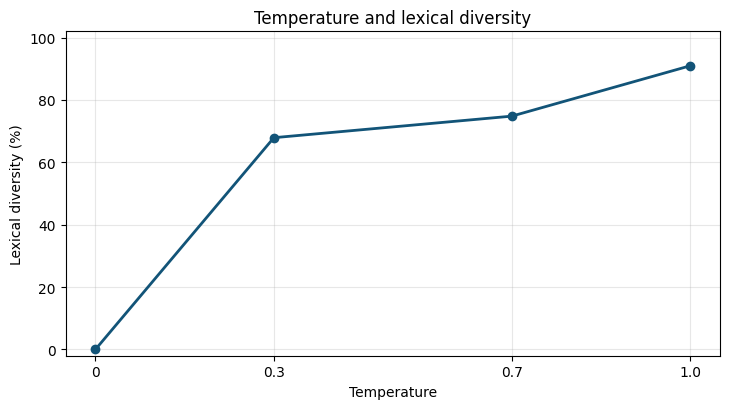

In [ ]:
temps = sorted((r for r in summary if r["parameter"] == "Temperature"), key=lambda r: r["value"])
assert len(temps) == 4
fig, ax = plt.subplots(figsize=(7.4, 4.2))
ax.plot([r["value"] for r in temps], [r["lexical_diversity_percent"] for r in temps],
        marker="o", linewidth=2, color="#125478")
ax.set(xlabel="Temperature", ylabel="Lexical diversity (%)",
       title="Temperature and lexical diversity",
       xticks=[0, .3, .7, 1.0], ylim=(-2, 102))
ax.set_xticklabels(["0", "0.3", "0.7", "1.0"])
ax.grid(alpha=.3)
fig.tight_layout()
fig.savefig(OUT / "temperature_vs_diversity.png", dpi=220)
plt.show()

## Export results and finish the worksheets
Download the archive. Add the manual scores in the scoring CSV or on the worksheets. Use the condition metrics for Worksheet C and add the means of the manual scores. Include the raw responses, the plotted graph, and your discussion answers.

In [ ]:
archive = Path("Week_06_Experiment_Results.zip")
result_names = [
    "metadata.json", "raw_responses.jsonl", "condition_metrics.csv",
    "student_scoring.csv", "temperature_vs_diversity.png"
]
with zipfile.ZipFile(archive, "w", compression=zipfile.ZIP_DEFLATED) as z:
    for name in result_names:
        z.write(OUT / name, arcname=name)
try:
    from google.colab import files
except ImportError:
    print(f"Archive saved at {archive.resolve()}")
else:
    files.download(str(archive))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>